# 22. Data overview: the New Glenn explosion at every station

A first look at the explosion at LC-36 on 2026-05-29 (UTC day 149), in physical units:

* **channel status**: which inputs had a working sensor (only the Centaur stations were recording; the
  Gems and SmartSolos had been recovered after Artemis II);
* **origin time** refined from the airwave arrival times (the configured 01:00:30 is provisional);
* **polarity** of the infraBSUs, from the first motion of the airwave;
* **record sections** of pressure (>0.5 Hz; infraBSU) and vertical ground velocity (1–30 Hz; Trillium),
  sorted by distance from LC-36 and scaled to each trace's peak (peak at the native rate printed at right;
  display decimated to 100 samples/s). Gem overflow intervals (`flovopy.ingest.gem_overflow`) would be
  shaded and blanked, but no Gem recorded this event;
* **spectrograms** of pressure and vertical velocity at the nearest working station, B20 (11.8 km);
* B20's **Chaparral M25 (DDF) against its infraBSU (DD1)**, and a first **peak pressure vs distance** table.

Correction: `newglenn_config.instrument_correct` (`ksclib.centaur.instrument_correct_centaur`, which falls
back to B14's first post-event response file and adds the Chaparral stage; Gems and SmartSolos would go
through `ksclib.instrument_correct`).

Output (`cfg.OUT_DIR / "22_data_overview"`): `channel_status.csv`, `origin_time_fit.csv`,
`data_overview.png`, `b20_chaparral_vs_infrabsu.png`, `peak_pressures.csv`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

import ksclib
from ksclib import physics
from ksclib.pressure import event_reduced_pressures
import newglenn_config as cfg

warnings.filterwarnings('ignore', message='ObsPy can not map unit')
O0 = cfg.ORIGIN                       # provisional origin time from newglenn.yaml
OUT = cfg.output_dir('22_data_overview')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
stations = cfg.station_table()
print(cfg.EVENT.name, O0, cfg.PAD, f'({cfg.EVENT.site_lat:.5f}, {cfg.EVENT.site_lon:.5f})')
print('output:', OUT)

New Glenn explosion 2026-05-29T01:00:30.000000Z LC36 (28.47056, -80.54220)
output: /private/tmp/claude-502/-Users-glennthompson-Developer-KSCRocketSeismoHydrology--claude-worktrees-newglenn-paper-7faf3d/222e5555-a5a8-4c87-811a-b45733cc6c5d/scratchpad/ngout/22_data_overview


## Read and correct

Five minutes before to 6.5 minutes after the provisional origin. `stream_clip_intervals` finds Gem
16-bit overflow intervals (steep shocks are not overflow); it returns nothing here because no Gem recorded.

In [2]:
raw = cfg.event_stream_raw(starttime=O0 - 300, endtime=O0 + 400)
clips = cfg.stream_clip_intervals(raw)
st = cfg.instrument_correct(raw)                       # polarity_reversed channels flipped
st_asrec = cfg.instrument_correct(raw, fix_polarity=False)
print(f'{len(raw)} raw channels from', sorted({tr.stats.station for tr in raw}))
print(f'{len(st)} corrected; Gem overflow intervals: {sum(len(v) for v in clips.values())}')

/Users/glennthompson/Developer/KSCRocketSeismoHydrology/.claude/worktrees/newglenn-paper-7faf3d/ksclib/src/ksclib/centaur.py:123: UserWarning: B14: no Centaur response before 2026-05-29T01:00:30.000000Z; using 1R.B14_20260614T135243Z.xml (16.5 days later)
  warnings.warn(str(m.message))


/Users/glennthompson/Developer/KSCRocketSeismoHydrology/.claude/worktrees/newglenn-paper-7faf3d/ksclib/src/ksclib/centaur.py:123: UserWarning: B14: no Centaur response before 2026-05-29T01:00:30.000000Z; using 1R.B14_20260614T135243Z.xml (16.5 days later)
  warnings.warn(str(m.message))


42 raw channels from ['B01', 'B03', 'B05', 'B14', 'B20', 'B24', 'B29']
42 corrected; Gem overflow intervals: 0


## Channel status

A Centaur input with nothing connected records only digitizer noise: about 2 counts rms on the Trillium
inputs and about 14 counts on the infrasound inputs at 500 samples/s. Inputs within 20% of the 24-bit
rail have a Trillium mass at its stop (or a clipped sensor). B03's Centaur channels are known to be faulty.

In [3]:
FULL_SCALE = 2 ** 23
rows = []
for tr in raw:
    n = tr.slice(O0 - 250, O0 - 50).data.astype(float)
    s = tr.slice(O0 - 40, O0 + 150).data.astype(float)
    cha = tr.stats.channel
    quiet = n.std() < (5 if cha.startswith('DH') else 25)
    railed = max(abs(s.min()), abs(s.max())) > 0.8 * FULL_SCALE
    status = ('faulty Centaur' if tr.stats.station in cfg.EXCLUDE_STATIONS_CENTAUR else
              'no sensor' if quiet else 'railed/clipped' if railed else 'ok')
    rows.append(dict(id=tr.id, station=tr.stats.station, channel=cha, fs=tr.stats.sampling_rate,
                     distance_km=stations.distance_km[tr.stats.station], noise_counts=n.std(),
                     min_counts=s.min(), max_counts=s.max(), status=status))
status = pd.DataFrame(rows).sort_values(['distance_km', 'channel']).set_index('id')
status.to_csv(OUT / 'channel_status.csv')
with pd.option_context('display.float_format', '{:.4g}'.format):
    display(status)
OK = set(status.index[status.status == 'ok'])

,station,channel,fs,distance_km,noise_counts,min_counts,max_counts,status
id,,,,,,,,
1R.B20.00.DD1,B20,DD1,100,11.79,331.3,-1.078e+05,2.872e+05,ok
1R.B20.00.DD2,B20,DD2,100,11.79,9.249,-976,-701,no sensor
1R.B20.00.DDF,B20,DDF,100,11.79,1.497e+05,-9.183e+06,9.398e+06,railed/clipped
1R.B20.00.DH1,B20,DH1,100,11.79,1.263e+04,-1.056e+04,1.48e+05,ok
1R.B20.00.DH2,B20,DH2,100,11.79,1.29e+04,-2.046e+04,1.503e+05,ok
1R.B20.00.DHZ,B20,DHZ,100,11.79,3.695e+04,4.358e+05,8.846e+05,ok
1R.B24.00.DD0,B24,DD0,500,15.55,13.19,-1523,-1368,no sensor
1R.B24.00.DD1,B24,DD1,500,15.55,13.44,693,874,no sensor
1R.B24.00.DD2,B24,DD2,500,15.55,13.27,362,516,no sensor


## infraBSU polarity

A blast wave starts with a compression. For each working infraBSU: the sign of the first excursion above
30% of the peak (0.5–5 Hz) and the correlation with B14 DD0, both as recorded (before the flips listed in
`newglenn.yaml` `polarity_reversed`).

In [4]:
ref = st_asrec.select(id='1R.B14.00.DD0')[0].copy().filter('bandpass', freqmin=0.5, freqmax=5)
pol = []
for tr in st_asrec:
    if tr.id not in OK or tr.stats.channel not in cfg.EVENT.infrabsu_channels:
        continue
    t = tr.copy().filter('bandpass', freqmin=0.5, freqmax=5).slice(O0 - 30, O0 + 60)
    a = t.data
    first = np.sign(a[np.argmax(np.abs(a) > 0.3 * np.abs(a).max())])
    r = np.nan
    if tr.stats.station == 'B14':
        w = (O0 + 22, O0 + 40)
        r = np.corrcoef(ref.slice(*w).data, tr.copy().filter('bandpass', freqmin=0.5, freqmax=5).slice(*w).data)[0, 1]
    pol.append(dict(id=tr.id, first_motion='compression' if first > 0 else 'rarefaction', corr_B14_DD0=r,
                    flipped=tr.id in cfg.POLARITY_REVERSED))
pol = pd.DataFrame(pol).set_index('id')
display(pol.round(2))
assert all((pol.first_motion == 'rarefaction') == pol.flipped), 'polarity_reversed in newglenn.yaml needs updating'

,first_motion,corr_B14_DD0,flipped
id,,,
1R.B05.00.DD0,rarefaction,NaN,True
1R.B14.00.DD0,compression,1.00,False
1R.B14.00.DD1,rarefaction,-0.99,True
1R.B14.00.DD2,rarefaction,-0.99,True
1R.B20.00.DD1,compression,NaN,False
1R.B29.00.DD0,compression,NaN,False


## Origin time from the airwave

The airwave onset at each working pressure channel is taken as the first sample above 20% of the
channel's peak (>0.5 Hz). A straight line $t = t_0 + d/c$ through the onsets gives the origin time and
an apparent sound speed; a fit with $c$ fixed at the still-air speed for 25 °C and 80% RH
(`ksclib.physics.compute_speed_of_sound`) is shown for comparison.

In [5]:
def onset(tr, frac=0.2):
    t = tr.copy().filter('highpass', freq=0.5, corners=4, zerophase=True).slice(O0 - 60, O0 + 120)
    a = np.abs(t.data)
    i = np.argmax(a > frac * a.max())
    return float(t.stats.starttime + i / t.stats.sampling_rate - O0), float(a.max())

picks = []
for tr in st:
    if tr.id in OK and tr.stats.channel.startswith('DD') and tr.stats.channel != 'DDF':
        t, pk = onset(tr)
        picks.append(dict(id=tr.id, station=tr.stats.station, distance_km=stations.distance_km[tr.stats.station],
                          onset_s=t, peak_pa=pk))
picks = pd.DataFrame(picks).sort_values('distance_km')
d, t = picks.distance_km.to_numpy() * 1000, picks.onset_s.to_numpy()
slope, t0_free = np.polyfit(d, t, 1)
c_free = 1 / slope
c25 = float(physics.compute_speed_of_sound(25.0, 80.0))
t0_fixed = float(np.mean(t - d / c25))
picks['resid_free_s'] = t - (t0_free + d / c_free)
picks['resid_fixed_s'] = t - (t0_fixed + d / c25)
ORIGIN = O0 + t0_free
fit = pd.DataFrame([dict(fit='free c', t0_rel_provisional_s=t0_free, origin_time=str(O0 + t0_free), c_mps=c_free,
                         rms_resid_s=np.sqrt(np.mean(picks.resid_free_s ** 2))),
                    dict(fit=f'c fixed {c25:.1f}', t0_rel_provisional_s=t0_fixed, origin_time=str(O0 + t0_fixed),
                         c_mps=c25, rms_resid_s=np.sqrt(np.mean(picks.resid_fixed_s ** 2)))])
fit.to_csv(OUT / 'origin_time_fit.csv', index=False)
display(picks.round(3)); display(fit.round(3))
print(f'Refined origin time {ORIGIN} ({t0_free:+.1f} s from the provisional {O0}); used below.')

,id,station,distance_km,onset_s,peak_pa,resid_free_s,resid_fixed_s
4,1R.B20.00.DD1,B20,11.793,6.630,364.401,0.059,-0.321
1,1R.B14.00.DD0,B14,19.312,28.516,235.947,-0.109,-0.073
2,1R.B14.00.DD1,B14,19.312,28.514,304.820,-0.111,-0.075
3,1R.B14.00.DD2,B14,19.312,28.516,244.015,-0.109,-0.073
5,1R.B29.00.DD0,B29,21.003,33.878,296.351,0.294,0.422
0,1R.B05.00.DD0,B05,21.304,34.442,255.530,-0.025,0.120


,fit,t0_rel_provisional_s,origin_time,c_mps,rms_resid_s
0,free c,-28.023,2026-05-29T01:00:01.977101Z,340.912,0.145
1,c fixed 347.5,-26.991,2026-05-29T01:00:03.008937Z,347.458,0.228


Refined origin time 2026-05-29T01:00:01.977101Z (-28.0 s from the provisional 2026-05-29T01:00:30.000000Z); used below.


## Record sections and spectrograms

Pressure: the working infraBSU channels (B20 DD1, B14 DD0–DD2, B29 DD0, B05 DD0). Vertical velocity: the
working Trilliums. B20 is at 100 samples/s; the others at 500. Times are after the refined origin.

In [6]:
T0, T1 = -10, 90
groups = {'pressure': [], 'velocity': []}
for tr in st:
    if tr.id not in OK:
        continue
    cha = tr.stats.channel
    k = 'pressure' if cha in cfg.EVENT.infrabsu_channels else 'velocity' if cha == 'DHZ' else None
    if not k:
        continue
    t = tr.copy()
    if k == 'pressure':
        t.filter('highpass', freq=0.5, corners=4, zerophase=True)
    else:                             # 1-30 Hz: B20's Trillium has strong tones near 15 and 35 Hz
        t.filter('bandpass', freqmin=1.0, freqmax=30.0, corners=4, zerophase=True)
    full = t.slice(ORIGIN + T0, ORIGIN + T1)
    m_full = cfg.clip_mask(full, clips.get(tr.id, []))
    peak_full = np.nanmax(np.abs(np.where(m_full, np.nan, full.data.astype(float))))
    if t.stats.sampling_rate > 100:
        t.filter('lowpass', freq=40, corners=8, zerophase=True)
        t.resample(100, no_filter=True)
    t = t.slice(ORIGIN + T0, ORIGIN + T1)
    t.data = np.where(cfg.clip_mask(t, clips.get(tr.id, [])), np.nan, t.data.astype(float))
    groups[k].append((stations.distance_km[tr.stats.station], tr.id, t, peak_full))
for k in groups:
    groups[k].sort(key=lambda x: (x[0], x[1]))
print({k: len(v) for k, v in groups.items()})

{'pressure': 6, 'velocity': 4}


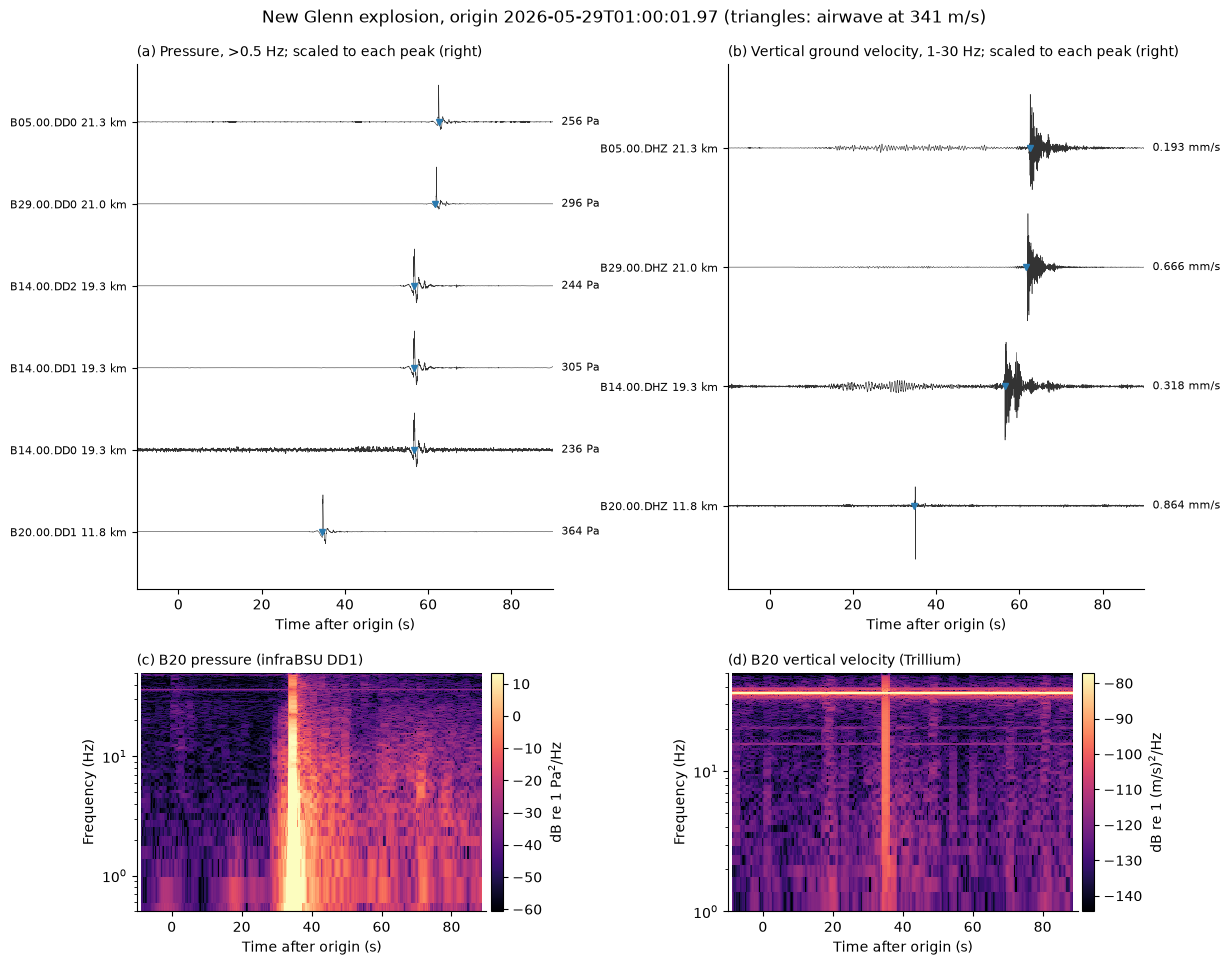

In [7]:
NEAR = 'B20'
fig = plt.figure(figsize=(13, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[2.2, 1], hspace=0.22, wspace=0.42)
for col, (k, scale, fmt) in enumerate((('pressure', 1, '{:.0f} Pa'), ('velocity', 1e3, '{:.3f} mm/s'))):
    ax = fig.add_subplot(gs[0, col])
    for i, (dk, sid, t, peak_full) in enumerate(groups[k]):
        y = t.data * scale
        ax.plot(t.times() + T0, i + 0.45 * y / np.nanmax(np.abs(y)), color='#333333', lw=0.4)
        for a, b in clips.get(sid, []):
            ax.axvspan(a - ORIGIN, b - ORIGIN, ymin=(i + 0.05) / len(groups[k]), ymax=(i + 0.95) / len(groups[k]),
                       color='#eb6834', alpha=0.25, lw=0)
        ax.text(T1 + 2, i, fmt.format(peak_full * scale), va='center', fontsize=8)
        ax.plot(dk * 1000 / c_free, i, 'v', color='#2a7ab0', ms=5)          # airwave at the fitted speed
    ax.set_yticks(range(len(groups[k])))
    ax.set_yticklabels([f"{sid.replace('1R.', '')} {dk:.1f} km" for dk, sid, _, _ in groups[k]], fontsize=8)
    ax.set(ylim=(-0.7, len(groups[k]) - 0.3), xlim=(T0, T1), xlabel='Time after origin (s)')
    ax.set_title(('(a) Pressure, >0.5 Hz' if k == 'pressure' else '(b) Vertical ground velocity, 1-30 Hz') +
                 '; scaled to each peak (right)', fontsize=10, loc='left')
for col, (sid, lab, unit, flo) in enumerate(((f'1R.{NEAR}.00.DD1', f'(c) {NEAR} pressure (infraBSU DD1)', 'Pa$^2$/Hz', 0.5),
                                             (f'1R.{NEAR}.00.DHZ', f'(d) {NEAR} vertical velocity (Trillium)', '(m/s)$^2$/Hz', 1.0))):
    tr = st.select(id=sid)[0].copy()
    tr.filter('highpass', freq=flo, corners=4, zerophase=True)
    s = tr.slice(ORIGIN + T0, ORIGIN + T1)
    fs = s.stats.sampling_rate
    f, tt, Sxx = spectrogram(s.data.astype(float), fs, nperseg=256, noverlap=224)
    db = 10 * np.log10(Sxx + 1e-30)
    ax = fig.add_subplot(gs[1, col])
    im = ax.pcolormesh(tt + T0, f, db, shading='auto', cmap='magma',
                       vmin=np.percentile(db, 5), vmax=np.percentile(db, 99.5))
    ax.set(yscale='log', ylim=(flo, fs / 2), xlim=(T0, T1), ylabel='Frequency (Hz)', xlabel='Time after origin (s)')
    ax.set_title(lab, fontsize=10, loc='left')
    fig.colorbar(im, ax=ax, pad=0.01, label=f'dB re 1 {unit}')
fig.suptitle(f'{cfg.EVENT.name}, origin {str(ORIGIN)[:22]} (triangles: airwave at {c_free:.0f} m/s)', y=0.93)
fig.savefig(OUT / 'data_overview.png', dpi=200, bbox_inches='tight')

## B20: Chaparral M25 (DDF) against the infraBSU (DD1)

Both sensors are on Centaur Sensor B, which was at 1 Vpp until the 2026-09-23 field visit. The raw DDF
counts reach the digitizer's full scale, so the Chaparral clipped. Its pressure scale (0.4 V/Pa in
`newglenn.yaml`, from the NRL entry used before; flovopy's station table assumes 0.05 V/Pa) is checked
against DD1 on the pre-arrival noise: coherence and the DDF/DD1 transfer amplitude |S_xy|/S_xx.

DDF raw counts -9182680 .. 9397804 (2^23 = 8388608)


,band_Hz,coherence,DDF_over_DD1
0,0.1-0.5,0.808,0.058
1,0.5-1,0.424,0.048
2,1-2,0.254,0.053
3,2-5,0.367,0.046
4,5-10,0.428,0.047
5,10-20,0.450,0.055


Relative to the infraBSU, the M25 behaves as 0.023 V/Pa (configured 0.4); clip level about 25 Pa at 1 Vpp


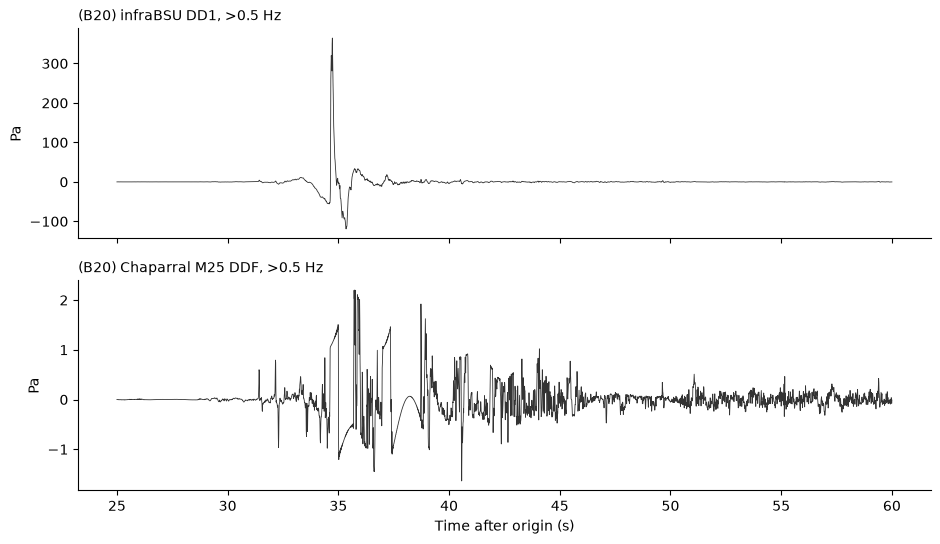

In [8]:
b = raw.select(station='B20')
ddf_raw = b.select(channel='DDF')[0].slice(ORIGIN, ORIGIN + 80)
print(f"DDF raw counts {ddf_raw.data.min():.0f} .. {ddf_raw.data.max():.0f} (2^23 = {FULL_SCALE})")
fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, (cha, lab) in zip(axs, (('DD1', 'infraBSU DD1'), ('DDF', 'Chaparral M25 DDF'))):
    tr = st.select(station='B20', channel=cha)[0].copy().filter('highpass', freq=0.5, corners=4, zerophase=True)
    s = tr.slice(ORIGIN + 25, ORIGIN + 60)
    ax.plot(s.times() + 25, s.data, lw=0.6, color='#333333')
    ax.set(ylabel='Pa'); ax.set_title(f'(B20) {lab}, >0.5 Hz', loc='left', fontsize=10)
axs[-1].set_xlabel('Time after origin (s)')
fig.savefig(OUT / 'b20_chaparral_vs_infrabsu.png', dpi=150, bbox_inches='tight')
from scipy.signal import coherence, csd, welch
x = st.select(station='B20', channel='DD1')[0].slice(ORIGIN - 280, ORIGIN - 20).data
y = st.select(station='B20', channel='DDF')[0].slice(ORIGIN - 280, ORIGIN - 20).data
f, coh = coherence(x, y, 100, nperseg=1024); _, sxy = csd(x, y, 100, nperseg=1024); _, sxx = welch(x, 100, nperseg=1024)
bands = [(0.1, 0.5), (0.5, 1), (1, 2), (2, 5), (5, 10), (10, 20)]
tf = pd.DataFrame([dict(band_Hz=f'{lo}-{hi}', coherence=coh[(f >= lo) & (f < hi)].mean(),
                        DDF_over_DD1=np.mean(np.abs(sxy) / sxx, where=(f >= lo) & (f < hi))) for lo, hi in bands])
display(tf.round(3))
g = tf.DDF_over_DD1.iloc[0]
v = cfg.ksclib.centaur.chaparral_config(cfg.EVENT)['V_per_Pa']
print(f'Relative to the infraBSU, the M25 behaves as {v * g:.3f} V/Pa (configured {v}); '
      f'clip level about {abs(ddf_raw.data).max() / (v * g * 16e6):.0f} Pa at 1 Vpp')

## Peak pressure against distance

Baseline-corrected positive and negative peaks (>0.5 Hz) and pressures reduced to 1 km by spherical
spreading (`ksclib.pressure.event_reduced_pressures`, ported from the AMOS-6 paper). For B14, the three
infraBSUs are averaged in the summary.

,id,distance_m,positive_peak_pa,negative_peak_pa,positive_peak_time_s,positive_reduced_pa
0,1R.B20.00.DD1,11793.38,364.40,-119.27,34.73,4297.53
1,1R.B14.00.DD0,19311.80,235.86,-84.49,56.54,4554.95
2,1R.B14.00.DD1,19311.80,304.82,-105.91,56.54,5886.55
3,1R.B14.00.DD2,19311.80,244.01,-82.22,56.54,4712.37
4,1R.B29.00.DD0,21002.68,296.35,-41.20,61.98,6224.16
5,1R.B05.00.DD0,21303.72,255.37,-59.28,62.51,5440.33


,distance_km,positive_peak_pa,positive_reduced_pa
station,,,
B20,11.79,364.40,4297.53
B14,19.31,261.56,5051.29
B29,21.00,296.35,6224.16
B05,21.30,255.37,5440.33


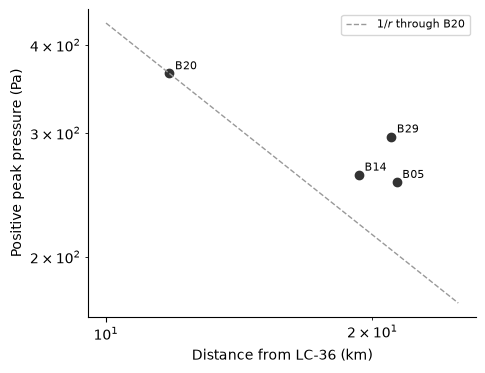

In [9]:
pp = st.copy().select(channel='DD?')
pp = pp.__class__([tr for tr in pp if tr.id in OK and tr.stats.channel != 'DDF'])
pp.filter('highpass', freq=0.5, corners=4, zerophase=True)
peaks = event_reduced_pressures(pp, cfg.EVENT, stations=stations, baseline=(t0_free - 20, t0_free - 1),
                                reference_distance_m=1000.0)
peaks['positive_peak_time_s'] -= t0_free; peaks['negative_peak_time_s'] -= t0_free   # after the refined origin
peaks.to_csv(OUT / 'peak_pressures.csv', index=False)
cols = ['id', 'distance_m', 'positive_peak_pa', 'negative_peak_pa', 'positive_peak_time_s', 'positive_reduced_pa']
display(peaks[cols].round(2))
summ = peaks.groupby('station').agg(distance_km=('distance_m', lambda x: x.iloc[0] / 1000),
                                    positive_peak_pa=('positive_peak_pa', 'mean'),
                                    positive_reduced_pa=('positive_reduced_pa', 'mean')).sort_values('distance_km')
display(summ.round(2))
fig, ax = plt.subplots(figsize=(5, 4))
ax.loglog(summ.distance_km, summ.positive_peak_pa, 'o', color='#333333')
for s_, r in summ.iterrows():
    ax.annotate(s_, (r.distance_km, r.positive_peak_pa), xytext=(4, 3), textcoords='offset points', fontsize=8)
dd = np.linspace(10, 25, 50)
p_ref = summ.positive_peak_pa.iloc[0] * summ.distance_km.iloc[0]
ax.loglog(dd, p_ref / dd, '--', color='#999999', lw=1, label='$1/r$ through B20')
ax.set(xlabel='Distance from LC-36 (km)', ylabel='Positive peak pressure (Pa)')
ax.legend(fontsize=8)
fig.savefig(OUT / 'peak_pressure_vs_distance.png', dpi=150, bbox_inches='tight')

## What the data show (first look)

Written from the run whose outputs are above; re-read if the configuration changes.

* **Stations.** Only the Centaur stations were recording. Working pressure: B20 DD1 (11.8 km), B14 DD0–DD2
  (19.3 km), B29 DD0 (21.0 km), B05 DD0 (21.3 km). Working vertical velocity: B20, B14, B29, B05 (B05's
  horizontals are near the rails). **B01, B03 and B24 record only digitizer noise on every channel**
  (about 2 counts rms on DH, 14 on DD: no sensors connected, or B03's known fault). B20 DD2 and the
  DD1/DD2 inputs at B05 and B29 are unconnected.
* **Polarity.** B14 DD1, B14 DD2 and B05 DD0 start with a rarefaction (B14 DD1/DD2 correlate at −0.99 with
  B14 DD0), so they are wired reversed; they are flipped through `polarity_reversed` in `newglenn.yaml`.
* **Origin time.** The six airwave onsets fit $t = t_0 + d/c$ with 0.15 s rms for $t_0$ = 01:00:01.98 UTC and
  $c$ = 341 m/s, 28 s before the provisional 01:00:30. With $c$ fixed at 347.5 m/s (25 °C, 80% RH) the origin
  is 01:00:03.0. Update `origin_time` in `newglenn.yaml` once checked against independent timing.
* **Amplitudes.** Positive peaks are 364 Pa at B20 (11.8 km) and 255–305 Pa at 19–21 km, well within the
  infraBSU/Centaur range at 1 Vpp (about ±11 kPa). That is a slower fall-off than $1/r$: the reduced pressure
  grows from 4.3 kPa·km at B20 to 5–6 kPa·km at 19–21 km. Two possible reasons: night-time ducting, or a
  low B20 peak because B20 samples at 100 Hz, not 500. Positive phases are 3–7× the negative ones.
* **Ground motion.** The largest vertical velocities (0.2–0.9 mm/s) come with the airwave (air-to-ground
  coupling). B14 and B05 also show a weak, roughly 5 Hz seismic wavetrain from about 15 s to the airwave,
  probably energy that travelled through the ground from the explosion. B20's Trillium has strong tones
  near 15 and 35 Hz (local machinery), so it is shown at 1–30 Hz.
* **B20 Chaparral** clipped at 1 Vpp (raw counts beyond ±2^23). Pre-arrival noise is coherent with DD1
  (0.81 at 0.1–0.5 Hz), with a flat DDF/DD1 ratio of 0.05 from 0.1 to 20 Hz. So, relative to the infraBSU,
  the M25 behaves as about 0.023 V/Pa: neither the configured 0.4 nor flovopy's 0.05.